# Level 1 — Image Processing Basics with the Flowers Dataset

A beginner-friendly notebook. Every code cell is full of comments, so you can learn simply by reading from top to bottom.

**Dataset:** Kaggle [`alxmamaev/flowers-recognition`](https://www.kaggle.com/datasets/alxmamaev/flowers-recognition) — photos of flowers in five classes: `daisy`, `dandelion`, `rose`, `sunflower`, `tulip`. The dataset is downloaded automatically with KaggleHub and is not included in this notebook.

## What you will learn

1. What a digital image really is (a grid of numbers)
2. How colour images are built from Red, Green and Blue channels
3. Resizing, cropping, flipping and rotating images
4. Changing brightness and contrast
5. Converting to grayscale and reading a histogram
6. Blurring (smoothing) to remove noise
7. Thresholding to separate object from background
8. Detecting edges with the Canny algorithm

## How to use this notebook

Run the cells **one after another from the top**. After each section, read the comments, look at the picture, and try the *Try it yourself* ideas at the end.

## 1. Import the Libraries

A *library* is a collection of ready-made tools. We import each one once and give it a short name.

In [1]:
import os                           # os: work with folders and file paths
import cv2                          # OpenCV: the main library for image processing
import kagglehub                    # kagglehub: downloads datasets from Kaggle
import numpy as np                  # NumPy: images are stored as NumPy arrays (grids of numbers)
import pandas as pd                 # pandas: tables (DataFrames) to organise file names
import matplotlib.pyplot as plt     # matplotlib: draws pictures and charts
from PIL import Image               # PIL (Pillow): opens image files

# A "random seed" makes random choices repeatable, so you get the same image every time you run the notebook
RANDOM_STATE = 42

## 2. Download the Dataset

`kagglehub.dataset_download` downloads the dataset the first time and stores a copy on your computer (a *cache*). On later runs it reuses that copy, so it is fast.

> If Kaggle asks for credentials, create a free Kaggle account and follow the KaggleHub instructions to set up an API token.

In [2]:
# Download the dataset (or reuse the cached copy) and get the folder where it was stored
dataset_path = kagglehub.dataset_download(
    "alxmamaev/flowers-recognition"
)

# Show where the files are on your computer
print("Dataset path:", dataset_path)

Dataset path: /kaggle/input/datasets/alxmamaev/flowers-recognition


## 3. Find the Images and Count Them

The dataset is organised as **one folder per flower type**. The folder name is the *label* (the correct answer) for every image inside it. We search for the folder that contains all five class folders, then build a table with one row per image.

In [3]:
# The five flower classes we expect to find (these are also the folder names)
CLASS_NAMES = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

# Image file types we accept. Other files (for example .py files) are ignored.
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# os.walk visits every folder inside dataset_path.
# We stop at the first folder that directly contains all five class folders.
dataset_root = None
for current_folder, sub_folders, file_names in os.walk(dataset_path):
    sub_folders.sort()                                    # sort so the search order is always the same
    if all(name in sub_folders for name in CLASS_NAMES):  # are all five class folders here?
        dataset_root = current_folder
        break

if dataset_root is None:
    raise FileNotFoundError("Could not find the five flower folders inside the dataset.")

print("Images are stored in:", dataset_root)

# Build a list of dictionaries, one per image: its path and its label
records = []
for class_name in CLASS_NAMES:
    class_folder = os.path.join(dataset_root, class_name)
    for file_name in sorted(os.listdir(class_folder)):
        if file_name.lower().endswith(IMAGE_EXTENSIONS):          # keep real image files only
            records.append({
                "image_path": os.path.join(class_folder, file_name),
                "label": class_name,
            })

# A DataFrame is a table: each row is one image, each column is one property
image_df = pd.DataFrame(records)

print("Total number of images:", len(image_df))
print("\nImages per class:")
print(image_df["label"].value_counts())

Images are stored in: /kaggle/input/datasets/alxmamaev/flowers-recognition/flowers
Total number of images: 4317

Images per class:
label
dandelion    1052
tulip         984
rose          784
daisy         764
sunflower     733
Name: count, dtype: int64


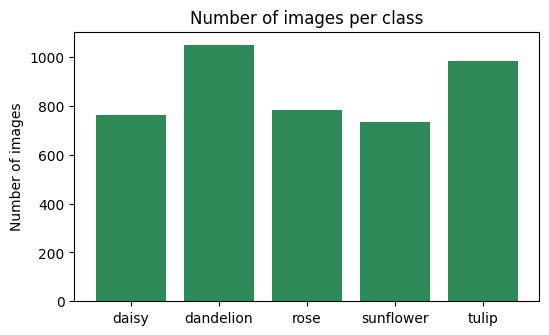

In [4]:
# Draw a bar chart so we can see at a glance whether the classes are balanced
class_counts = image_df["label"].value_counts().reindex(CLASS_NAMES)

plt.figure(figsize=(6, 3.5))
plt.bar(class_counts.index, class_counts.values, color="seagreen")
plt.title("Number of images per class")
plt.ylabel("Number of images")
plt.show()

## 4. Choose One Image to Study

To keep things simple we will apply every operation to **one** image. Change `CLASS_TO_STUDY` to any of the five class names to explore a different flower.

In [5]:
CLASS_TO_STUDY = "sunflower"        # try: "daisy", "dandelion", "rose", "tulip"

# Keep only the rows of the chosen class, then pick ONE random row.
# random_state makes the "random" choice the same every time.
sample_row = (
    image_df[image_df["label"] == CLASS_TO_STUDY]
    .sample(n=1, random_state=RANDOM_STATE)
    .iloc[0]
)

print("Selected image:", sample_row["image_path"])
print("Class:", sample_row["label"])

Selected image: /kaggle/input/datasets/alxmamaev/flowers-recognition/flowers/sunflower/8929213942_5544191250_n.jpg
Class: sunflower


## 5. What Is an Image? — A Grid of Numbers

A digital image is a grid of tiny squares called **pixels**. Each pixel stores numbers describing its colour. A computer does not "see" a flower — it sees an array of numbers.

* **Height** = number of pixel rows
* **Width** = number of pixel columns
* **Channels** = numbers per pixel (3 for colour: Red, Green, Blue)

Each number is usually an integer from **0** (none of that colour) to **255** (the maximum).

> A note on colour order: Pillow and matplotlib use **RGB** order. OpenCV normally reads files in **BGR** order. Because we load images with Pillow, our arrays are already RGB, which is what OpenCV's colour conversion functions below expect.

In [6]:
# Open the image file with Pillow and convert it to RGB (so it always has exactly 3 channels)
pil_image = Image.open(sample_row["image_path"]).convert("RGB")

# Convert the Pillow image into a NumPy array. Now it is just numbers.
image_rgb = np.array(pil_image)

# NumPy arrays have a "shape": (height, width, channels)
height, width, channels = image_rgb.shape

print("Shape (height, width, channels):", image_rgb.shape)
print("Height:", height, "pixels")
print("Width:", width, "pixels")
print("Channels:", channels)
print("Data type:", image_rgb.dtype, "(uint8 = whole numbers from 0 to 255)")
print("Smallest pixel value:", image_rgb.min())
print("Largest pixel value:", image_rgb.max())
print("Total number of values stored:", image_rgb.size)

# Show the very first pixel (top-left corner): three numbers [Red, Green, Blue]
print("\nTop-left pixel [R, G, B]:", image_rgb[0, 0])

Shape (height, width, channels): (213, 320, 3)
Height: 213 pixels
Width: 320 pixels
Channels: 3
Data type: uint8 (uint8 = whole numbers from 0 to 255)
Smallest pixel value: 0
Largest pixel value: 255
Total number of values stored: 204480

Top-left pixel [R, G, B]: [124 135  77]


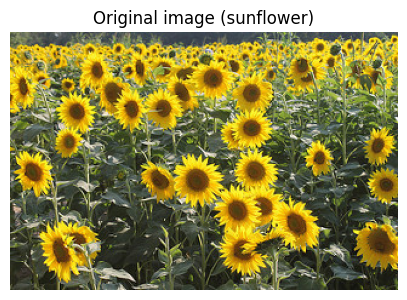

In [7]:
# plt.imshow draws an array as a picture
plt.figure(figsize=(5, 5))
plt.imshow(image_rgb)
plt.title(f"Original image ({CLASS_TO_STUDY})")
plt.axis("off")             # hide the axis numbers for a cleaner picture
plt.show()

## 6. The Red, Green and Blue Channels

A colour image is three grids stacked together — one per colour. Mixing red, green and blue light in different amounts creates every colour we see. Below, each channel is shown on its own.

* A **bright** area in the *Red* channel means that part of the image contains a lot of red.
* A sunflower is yellow (red + green), so its petals should look bright in both the red and green channels but dark in blue.

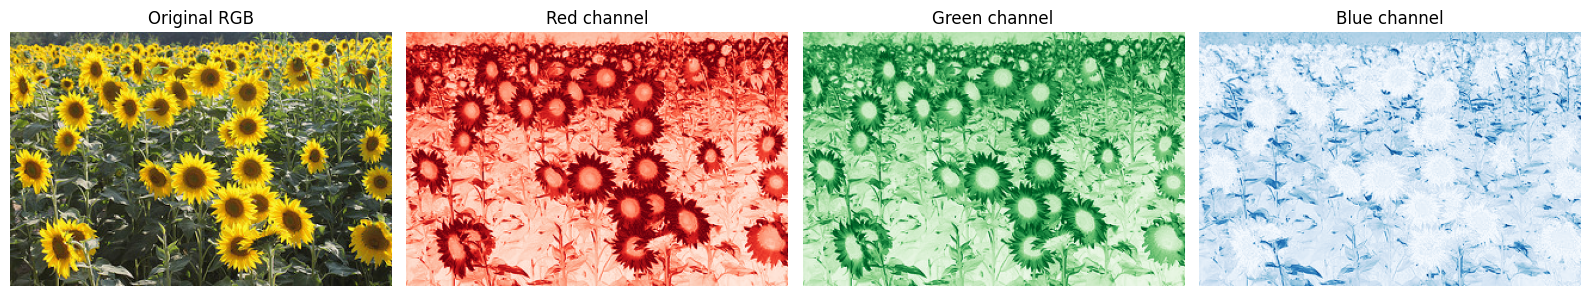

In [8]:
# Slicing with [:, :, 0] means: every row, every column, channel number 0 (Red)
red_channel   = image_rgb[:, :, 0]
green_channel = image_rgb[:, :, 1]
blue_channel  = image_rgb[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))     # one row with four pictures

axes[0].imshow(image_rgb);                   axes[0].set_title("Original RGB")
axes[1].imshow(red_channel,   cmap="Reds");  axes[1].set_title("Red channel")
axes[2].imshow(green_channel, cmap="Greens"); axes[2].set_title("Green channel")
axes[3].imshow(blue_channel,  cmap="Blues"); axes[3].set_title("Blue channel")

for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

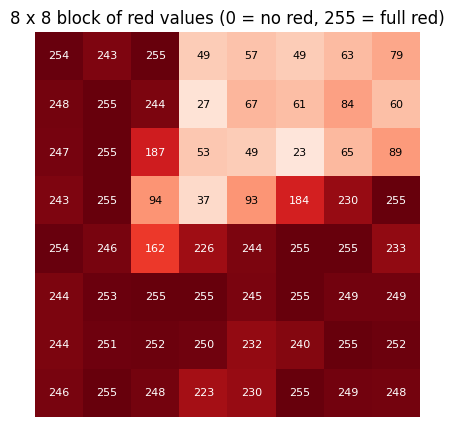

In [9]:
# Look at the actual numbers: take a tiny 8 x 8 block of pixels from the middle of the red channel
centre_row, centre_col = height // 2, width // 2
patch = red_channel[centre_row:centre_row + 8, centre_col:centre_col + 8]

fig, axis = plt.subplots(figsize=(5, 5))
axis.imshow(patch, cmap="Reds", vmin=0, vmax=255)   # colour each square by its value

# Write the number of each pixel on top of its square
for row in range(patch.shape[0]):
    for col in range(patch.shape[1]):
        axis.text(col, row, int(patch[row, col]), ha="center", va="center", fontsize=8,
                  color="white" if patch[row, col] > 128 else "black")

axis.set_title("8 x 8 block of red values (0 = no red, 255 = full red)")
axis.axis("off")
plt.show()

## 7. Resizing

Resizing changes the number of pixels. Many programs need all images to have the **same size**, so resizing is one of the most common steps.

> `cv2.resize` expects the new size as **(width, height)** — the opposite order of the array shape `(height, width)`. This is a very common beginner mistake!

Original shape: (213, 320, 3)
Resized shape:  (128, 128, 3)


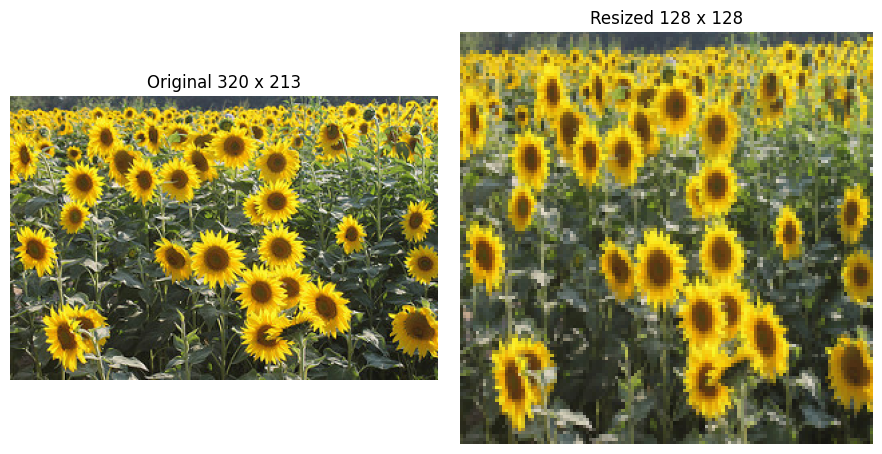

In [10]:
# New size: 128 pixels wide and 128 pixels high
new_width, new_height = 128, 128

# INTER_AREA is a good "interpolation" method when making an image smaller.
# Interpolation = how OpenCV calculates the colour of the new pixels.
resized_image = cv2.resize(image_rgb, (new_width, new_height), interpolation=cv2.INTER_AREA)

print("Original shape:", image_rgb.shape)
print("Resized shape: ", resized_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(image_rgb);     axes[0].set_title(f"Original {width} x {height}")
axes[1].imshow(resized_image); axes[1].set_title("Resized 128 x 128")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

# Note: the flower looks a little squashed or stretched because the original was not square.
# Resizing to a different shape changes the proportions (the "aspect ratio").

## 8. Cropping

Cropping keeps only a rectangular part of the image. In NumPy this is simply **slicing** the array: `image[row_start:row_end, col_start:col_end]`. A *centre crop* keeps the middle, where the main object usually is.

Cropped shape: (106, 160, 3)


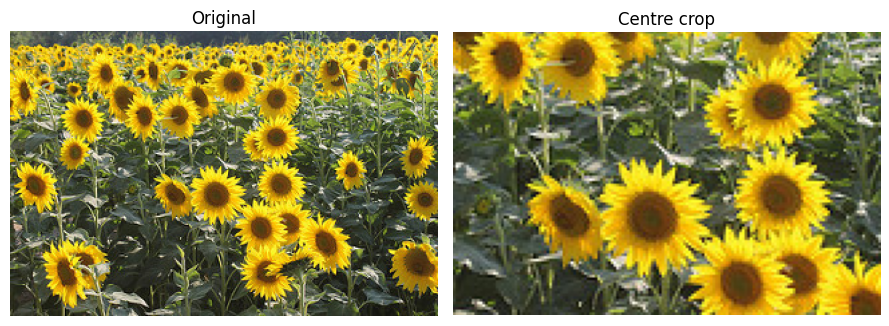

In [11]:
# We keep the middle half of the image in both directions
crop_height, crop_width = height // 2, width // 2

# Find where the crop starts so that it is centred
top  = (height - crop_height) // 2
left = (width - crop_width) // 2

# Slice rows from "top" to "top + crop_height" and columns from "left" to "left + crop_width"
cropped_image = image_rgb[top:top + crop_height, left:left + crop_width]

print("Cropped shape:", cropped_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(image_rgb);     axes[0].set_title("Original")
axes[1].imshow(cropped_image); axes[1].set_title("Centre crop")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 9. Flipping

Flipping mirrors the image. `cv2.flip(image, flip_code)`:

* `1` → flip **horizontally** (left ↔ right)
* `0` → flip **vertically** (top ↔ bottom)
* `-1` → flip both

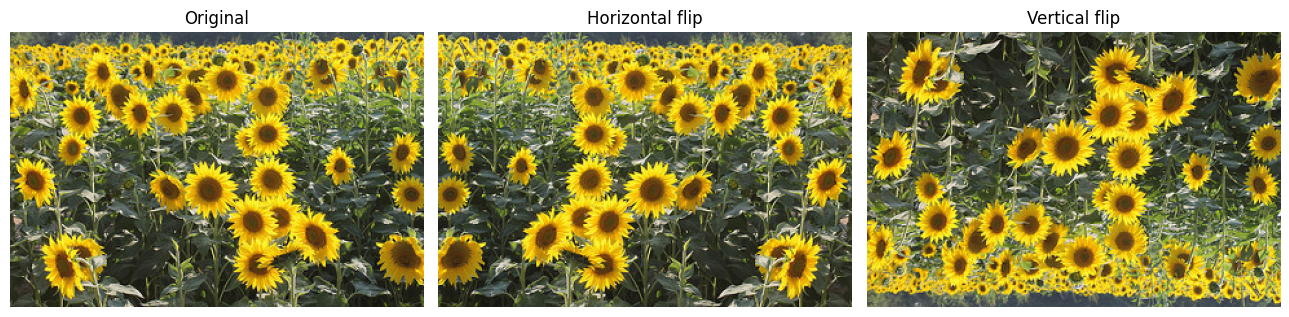

In [12]:
flipped_horizontal = cv2.flip(image_rgb, 1)     # mirror left-right
flipped_vertical   = cv2.flip(image_rgb, 0)     # mirror top-bottom

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(image_rgb);          axes[0].set_title("Original")
axes[1].imshow(flipped_horizontal); axes[1].set_title("Horizontal flip")
axes[2].imshow(flipped_vertical);   axes[2].set_title("Vertical flip")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 10. Rotating

Rotation turns the image around a centre point. OpenCV does this in two steps:

1. `cv2.getRotationMatrix2D(centre, angle, scale)` builds a small "recipe" (a matrix) for the rotation. A positive angle turns the image **counter-clockwise**.
2. `cv2.warpAffine(image, matrix, size)` applies the recipe to every pixel.

The corners that appear after rotating have no data, so they are filled with black.

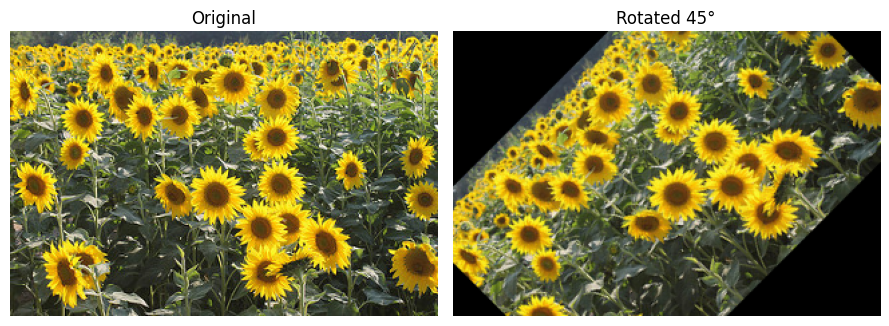

In [13]:
angle = 45                                   # degrees (try -30, 90, 180...)
centre = (width // 2, height // 2)           # rotate around the middle of the image: (x, y)

# Step 1: build the rotation recipe. Scale 1.0 means "keep the same size".
rotation_matrix = cv2.getRotationMatrix2D(centre, angle, 1.0)

# Step 2: apply it. The last argument is the output size as (width, height).
rotated_image = cv2.warpAffine(image_rgb, rotation_matrix, (width, height))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(image_rgb);     axes[0].set_title("Original")
axes[1].imshow(rotated_image); axes[1].set_title(f"Rotated {angle}°")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 11. Brightness and Contrast

A simple formula changes both:

$$\text{new pixel} = \alpha \times \text{old pixel} + \beta$$

* **β (beta)** is added to every pixel → changes **brightness** (positive = brighter, negative = darker).
* **α (alpha)** multiplies every pixel → changes **contrast** (above 1 = more contrast, below 1 = less).

`cv2.convertScaleAbs` applies the formula and keeps results between 0 and 255 (values outside that range are *clipped*).

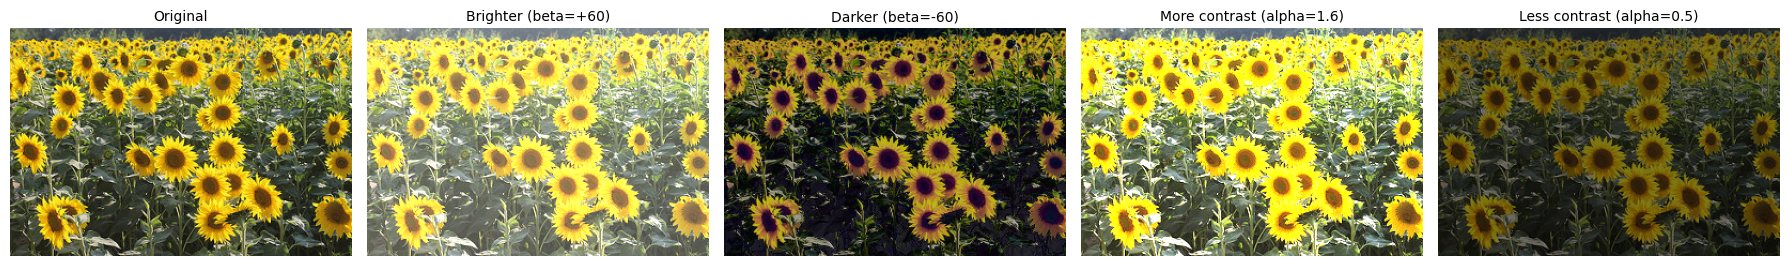

In [14]:
brighter     = cv2.convertScaleAbs(image_rgb, alpha=1.0, beta=60)    # add 60 to every value
darker       = cv2.convertScaleAbs(image_rgb, alpha=1.0, beta=-60)   # subtract 60 from every value
more_contrast = cv2.convertScaleAbs(image_rgb, alpha=1.6, beta=0)    # multiply by 1.6
less_contrast = cv2.convertScaleAbs(image_rgb, alpha=0.5, beta=0)    # multiply by 0.5

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for axis, (title, picture) in zip(axes, [
    ("Original", image_rgb), ("Brighter (beta=+60)", brighter), ("Darker (beta=-60)", darker),
    ("More contrast (alpha=1.6)", more_contrast), ("Less contrast (alpha=0.5)", less_contrast),
]):
    axis.imshow(picture)
    axis.set_title(title, fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 12. Grayscale and the Histogram

A **grayscale** image has just one number per pixel (0 = black, 255 = white) instead of three. It is smaller and simpler, and many techniques (blurring, thresholding, edge detection) work on grayscale.

OpenCV combines the channels using a weighted average that matches how bright each colour looks to the human eye (green counts the most).

A **histogram** counts how many pixels have each brightness value. It shows whether an image is mostly dark, mostly bright, or well spread out.

Colour shape:     (213, 320, 3)
Grayscale shape:  (213, 320) (only one value per pixel)
Average brightness: 113.4 (0 = black, 255 = white)


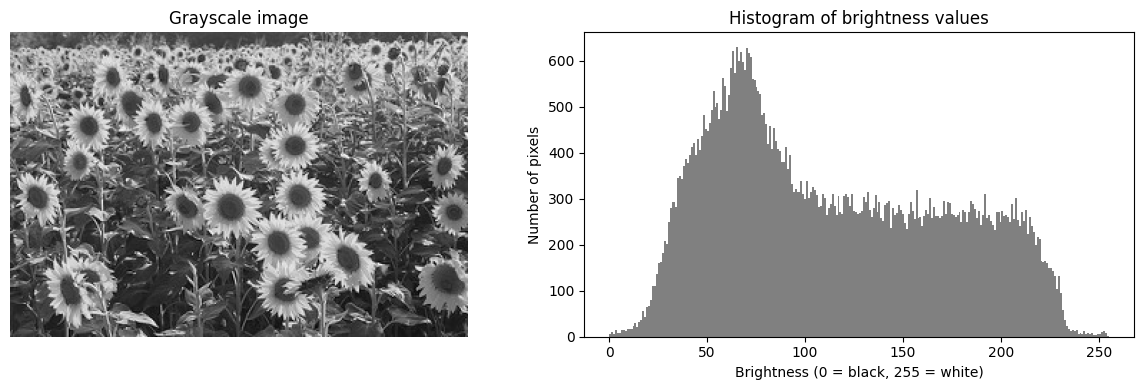

In [15]:
# Convert RGB -> grayscale. The shape changes from (height, width, 3) to (height, width).
gray_image = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

print("Colour shape:    ", image_rgb.shape)
print("Grayscale shape: ", gray_image.shape, "(only one value per pixel)")
print("Average brightness:", round(float(gray_image.mean()), 1), "(0 = black, 255 = white)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# cmap="gray" tells matplotlib to draw single-channel data in shades of gray
axes[0].imshow(gray_image, cmap="gray")
axes[0].set_title("Grayscale image")
axes[0].axis("off")

# ravel() flattens the grid into one long list so we can count values
axes[1].hist(gray_image.ravel(), bins=256, range=(0, 255), color="gray")
axes[1].set_title("Histogram of brightness values")
axes[1].set_xlabel("Brightness (0 = black, 255 = white)")
axes[1].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

## 13. Blurring (Smoothing)

Photos contain tiny random variations called **noise**. Blurring replaces each pixel by an average of its neighbours, which smooths the noise away (and also softens fine detail).

**Gaussian blur** uses a weighted average where nearer neighbours count more. The *kernel size* is the size of the neighbourhood: a bigger kernel gives a stronger blur. It must be an **odd** number (3, 5, 7, ...).

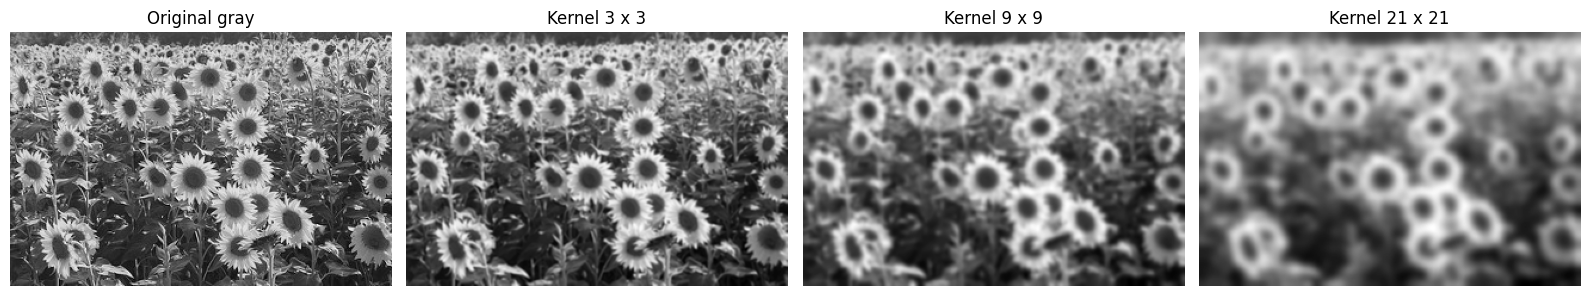

In [16]:
# The last argument 0 lets OpenCV choose the amount of spread automatically
blur_small  = cv2.GaussianBlur(gray_image, (3, 3), 0)     # light blur
blur_medium = cv2.GaussianBlur(gray_image, (9, 9), 0)     # medium blur
blur_large  = cv2.GaussianBlur(gray_image, (21, 21), 0)   # strong blur

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for axis, (title, picture) in zip(axes, [
    ("Original gray", gray_image), ("Kernel 3 x 3", blur_small),
    ("Kernel 9 x 9", blur_medium), ("Kernel 21 x 21", blur_large),
]):
    axis.imshow(picture, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 14. Thresholding

Thresholding turns a grayscale image into a **black-and-white** image: pixels brighter than a *threshold* become white (255), the rest become black (0). It is a simple way to separate an object from its background.

* **Fixed threshold:** you choose the number (for example 127).
* **Otsu's method:** the computer chooses the best threshold automatically by looking at the histogram.

We blur first, because noise can create many small speckles in the result.

Fixed threshold used: 127.0
Otsu threshold chosen automatically: 118.0


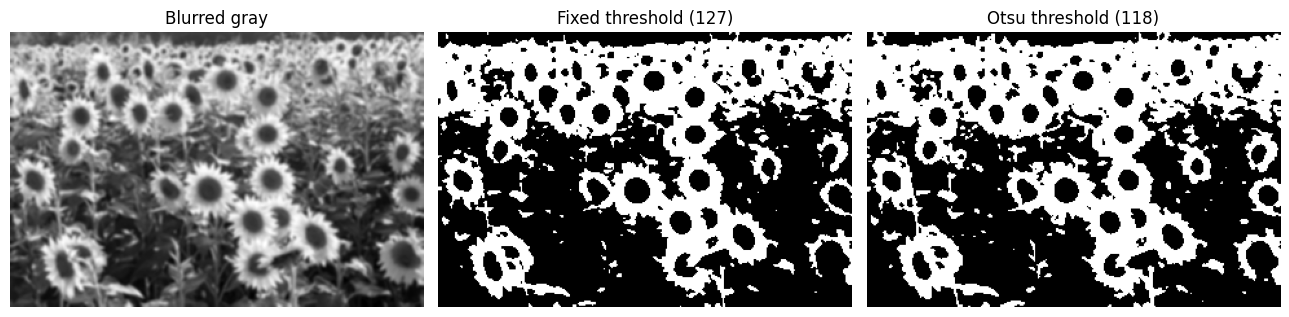

In [17]:
# Smooth the image first so noise does not create speckles
smooth_gray = cv2.GaussianBlur(gray_image, (5, 5), 0)

# Fixed threshold: pixels > 127 become 255 (white), all others become 0 (black)
# cv2.threshold returns two things: the threshold used, and the resulting image
fixed_value, fixed_binary = cv2.threshold(smooth_gray, 127, 255, cv2.THRESH_BINARY)

# Otsu: we pass 0 as the threshold and add THRESH_OTSU; OpenCV finds the best value itself
otsu_value, otsu_binary = cv2.threshold(smooth_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Fixed threshold used:", fixed_value)
print("Otsu threshold chosen automatically:", otsu_value)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(smooth_gray, cmap="gray");   axes[0].set_title("Blurred gray")
axes[1].imshow(fixed_binary, cmap="gray");  axes[1].set_title("Fixed threshold (127)")
axes[2].imshow(otsu_binary, cmap="gray");   axes[2].set_title(f"Otsu threshold ({otsu_value:.0f})")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

# Whether the flower ends up white or black depends on whether it is brighter than the background.

## 15. Edge Detection (Canny)

An **edge** is a place where brightness changes quickly — for example the outline of a petal. The **Canny** algorithm finds thin, clean edges using two thresholds:

* pixels with a change **above the high threshold** are definitely edges;
* pixels **below the low threshold** are rejected;
* pixels in between are kept only if they touch a definite edge.

Lower thresholds find more edges (including noise); higher thresholds find fewer.

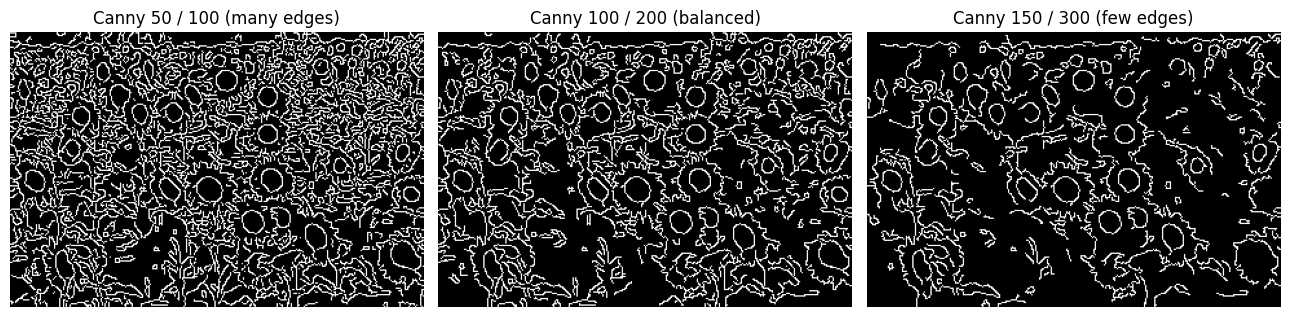

In [18]:
# Canny(image, low_threshold, high_threshold). The result is white edges on a black background.
edges_many = cv2.Canny(smooth_gray, 50, 100)      # sensitive: finds many edges
edges_some = cv2.Canny(smooth_gray, 100, 200)     # balanced
edges_few  = cv2.Canny(smooth_gray, 150, 300)     # strict: finds only strong edges

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for axis, (title, picture) in zip(axes, [
    ("Canny 50 / 100 (many edges)", edges_many),
    ("Canny 100 / 200 (balanced)", edges_some),
    ("Canny 150 / 300 (few edges)", edges_few),
]):
    axis.imshow(picture, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 16. Summary Picture

Finally, we place several results side by side and save the figure as a PNG file.

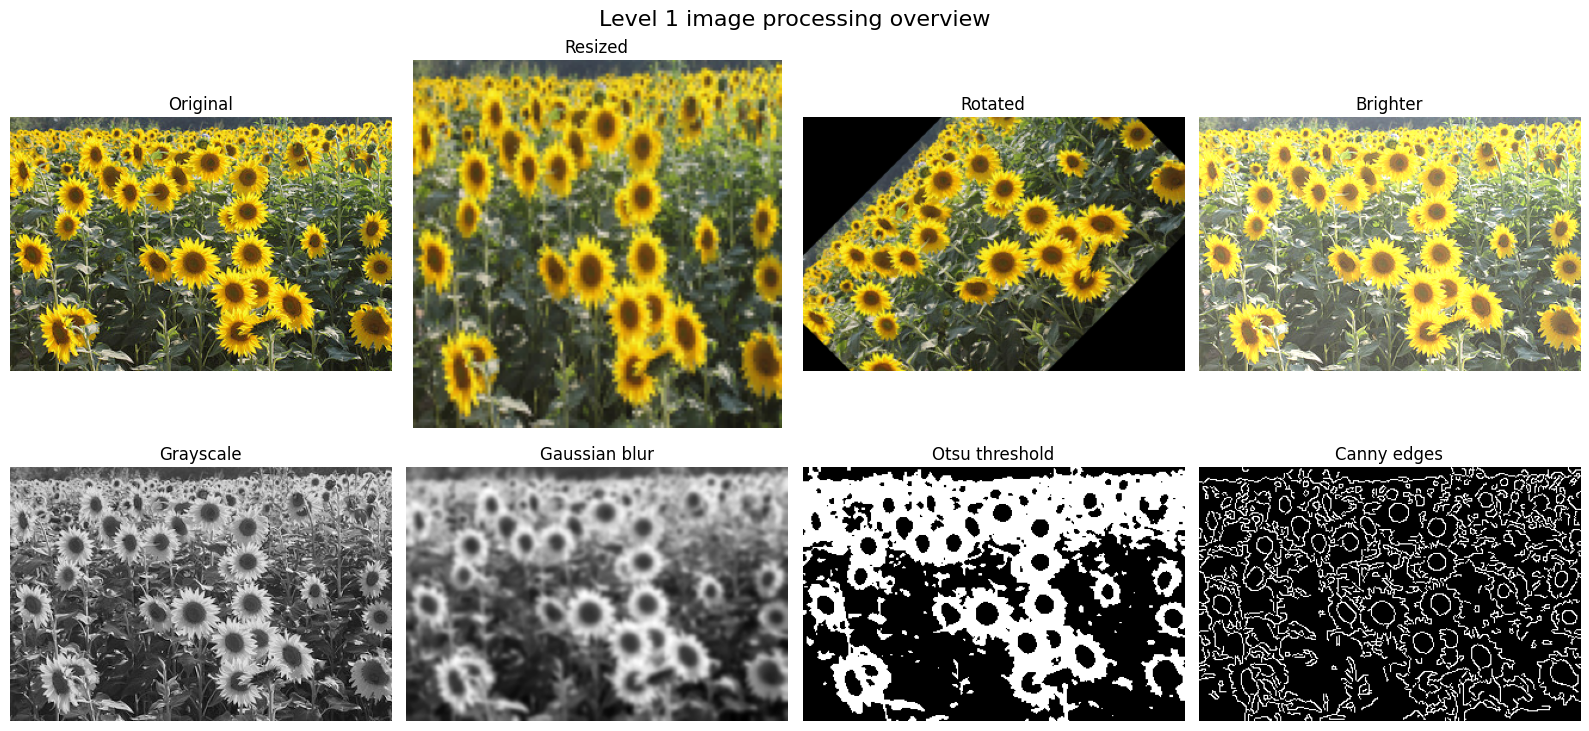

Saved: outputs/level1_overview.png


In [19]:
# Collect (title, picture, is_gray) for the images we want in the summary
summary_items = [
    ("Original", image_rgb, False),
    ("Resized", resized_image, False),
    ("Rotated", rotated_image, False),
    ("Brighter", brighter, False),
    ("Grayscale", gray_image, True),
    ("Gaussian blur", blur_medium, True),
    ("Otsu threshold", otsu_binary, True),
    ("Canny edges", edges_some, True),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))      # 2 rows x 4 columns
for axis, (title, picture, is_gray) in zip(axes.ravel(), summary_items):
    axis.imshow(picture, cmap="gray" if is_gray else None)
    axis.set_title(title)
    axis.axis("off")
plt.suptitle("Level 1 image processing overview", fontsize=16)
plt.tight_layout()

# Create the output folder if it does not exist yet, then save the figure
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/level1_overview.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: outputs/level1_overview.png")

## Recap

| Idea | Key code |
|---|---|
| Image = grid of numbers | `np.array(Image.open(path).convert("RGB"))` |
| Size of an image | `image.shape` → (height, width, channels) |
| Resize | `cv2.resize(image, (width, height))` |
| Crop | `image[row_start:row_end, col_start:col_end]` |
| Flip | `cv2.flip(image, 1)` |
| Rotate | `cv2.getRotationMatrix2D` + `cv2.warpAffine` |
| Brightness / contrast | `cv2.convertScaleAbs(image, alpha, beta)` |
| Grayscale | `cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)` |
| Blur | `cv2.GaussianBlur(image, (k, k), 0)` |
| Threshold | `cv2.threshold(..., cv2.THRESH_OTSU)` |
| Edges | `cv2.Canny(image, low, high)` |

